# Determinants of Student Retention Intention at a Private Higher Education Institution in South Africa
## Quantitative analysis notebook

**Researcher:** Phalanndwa Delron Munyai (ST10356476) · **Supervisor:** Ms L Njokwe · **Postgraduate Diploma in Data Analytics, The IIE**

This notebook reproduces every statistic reported in Chapter 4 of the research report. It follows the analysis plan in Section 3.9:

| Step | Section in notebook | Report section |
|---|---|---|
| Data loading, consent screening, coding | 1–3 | 3.8 |
| Data-quality screening and missing data | 4 | 3.8, 4.2 |
| Sample profile | 5 | 4.3 |
| Reliability and factor analysis | 6–7 | 4.4 |
| Descriptive statistics | 8 | 4.5 |
| Correlations | 9 | 4.6 |
| Multiple regression, diagnostics, dominance analysis, robustness | 10–13 | 4.7 |
| Group comparisons | 14–15 | 4.8 |
| Non-response bias check | 16 | 4.2 |
| Exploratory item-level analysis | 17 | 4.9 |


## 0. Setup

In [1]:
# If any library is missing, uncomment and run:
# %pip install pandas numpy scipy statsmodels pingouin factor_analyzer matplotlib openpyxl

import itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import pingouin as pg
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

# Compatibility patch: factor_analyzer 0.5 uses an argument removed in newer scikit-learn.
import factor_analyzer.factor_analyzer as _fam
from sklearn.utils import check_array as _ca
def _check_array(*a, force_all_finite=None, **k):
    if force_all_finite is not None:
        k["ensure_all_finite"] = force_all_finite
    return _ca(*a, **k)
_fam.check_array = _check_array

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9c9b95"

DATA_PATH = "Determinants_of_Student_Retention_in_Private_Higher_Education_Institutions_In_South_Africa1-120.xlsx"

def fmt_p(p):
    """APA-style p-value: exact to three decimals, '< .001' when very small."""
    return "< .001" if p < .001 else f"{p:.3f}".lstrip("0")

## 1. Load the data and apply the consent screen
The first question on the form asked for consent. Respondents who declined were not shown the questionnaire and are excluded.

In [2]:
raw = pd.read_excel(DATA_PATH)
consent_col = raw.columns[6]
print(f"Records in export: {len(raw)}")
display(raw[consent_col].value_counts().rename("n").to_frame())

df = raw[raw[consent_col].str.startswith("I agree")].copy()
print(f"Analytical sample (consented): n = {len(df)}")

Records in export: 120


,n
"By ticking 'I Agree' below, you confirm that: You have read and understood the information aboveYou are 18 years of age or olderYou understand that your participation is voluntary and you may with...",
I agree and wish to proceed with the survey,119
I wish to not proceed with the survey,1


Analytical sample (consented): n = 119


In [3]:
# Data collection window and completion times
start = pd.to_datetime(df["Start time"]); end = pd.to_datetime(df["Completion time"])
df["duration_s"] = (end - start).dt.total_seconds().values
by_day = start.dt.date.value_counts().sort_index()
print("First response:", start.min(), "| Last completion:", end.max())
print(f"Responses on 15 Sept: {by_day.iloc[0]} ({100*by_day.iloc[0]/len(df):.1f}%); by 16 Sept: {by_day.iloc[:2].sum()} ({100*by_day.iloc[:2].sum()/len(df):.1f}%)")
d = df["duration_s"]
print(f"Completion time: median {d.median():.0f} s, IQR {d.quantile(.25):.1f}–{d.quantile(.75):.0f} s, min {d.min():.0f} s, max {d.max():.0f} s")
by_day.rename("responses").to_frame().T

First response: 2026-09-15 10:49:23 | Last completion: 2026-11-02 16:03:39
Responses on 15 Sept: 76 (63.9%); by 16 Sept: 92 (77.3%)
Completion time: median 295 s, IQR 213.5–440 s, min 6 s, max 1883 s


Start time,2026-09-15,2026-09-16,2026-09-17,2026-09-18,2026-09-20,2026-09-21,2026-09-22,2026-09-23,2026-09-25,2026-09-27,2026-09-28,2026-09-30,2026-10-09,2026-11-02
responses,76,16,6,4,2,2,1,1,1,1,1,1,6,1


## 2. Rename variables and convert Likert responses to numbers
Likert answers were exported as text (e.g. `"5 - Strongly Agree"`, `"4"`); the first character is the score.

In [4]:
ren = {raw.columns[7]: "age", raw.columns[8]: "gender", raw.columns[9]: "province", raw.columns[10]: "year",
       raw.columns[11]: "qual", raw.columns[12]: "employ", raw.columns[13]: "funding"}
item_text = {}
for c in raw.columns[14:49]:
    code_ = c.strip().split(".")[0]
    ren[c] = code_
    item_text[code_] = c.strip().split(". ", 1)[1].strip()
item_text["B3"] = item_text["B3"].rstrip(" 3").strip()   # stray character in the form heading
df = df.rename(columns=ren)

B = [f"B{i}" for i in range(1, 13)]   # Institutional factors
C = [f"C{i}" for i in range(1, 9)]    # Academic engagement
D = [f"D{i}" for i in range(1, 11)]   # Student satisfaction
E = [f"E{i}" for i in range(1, 6)]    # Retention intention
ALL = B + C + D + E

to_num = lambda v: np.nan if pd.isna(v) else float(str(v).strip()[0])
for c in ALL:
    df[c] = df[c].map(to_num)
print("Values found in Likert items:", sorted(pd.unique(df[ALL].values.ravel()[~np.isnan(df[ALL].values.ravel())])))

Values found in Likert items: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


## 3. Recode demographic variables
* **Employment:** `Still a student` (open text) → *Not employed*. For comparisons: *Employed* = part-time, full-time or self-employed.
* **Funding:** the open-text answer `Personal/family funds...for now` → *Personal/family funds*; `Scholarship` merged with `Private bursary`. For comparisons: *Personal/family* vs *Other sources*.
* **Age:** 26–30, 31–35 and 36+ merged into *26 and older* (n = 8) for comparisons.

In [5]:
def clean_fund(v):
    if pd.isna(v): return np.nan
    v = str(v).lower()
    if v.startswith("personal"): return "Personal/family funds"
    if "combination" in v: return "Combination"
    if "loan" in v: return "Student loan"
    if "bursary" in v or "scholarship" in v: return "Bursary/scholarship"
    return "Other"

def clean_emp(v):
    if pd.isna(v): return np.nan
    v = str(v)
    if v.startswith("Part"): return "Part-time employed"
    if v.startswith("Full"): return "Full-time employed"
    if v.startswith("Self"): return "Self-employed"
    return "Not employed"          # 'Unemployed' and 'Still a student'

df["funding_c"] = df["funding"].map(clean_fund)
df["fund2"] = df["funding_c"].map(lambda v: np.nan if pd.isna(v) else ("Personal/family" if v == "Personal/family funds" else "Other sources"))
df["employ_c"] = df["employ"].map(clean_emp)
df["employed"] = df["employ_c"].map(lambda v: np.nan if pd.isna(v) else ("Employed" if v != "Not employed" else "Not employed"))
df["year_c"] = df["year"].map(lambda v: np.nan if pd.isna(v) else str(v).replace(" Year", "").replace("1st", "First")
                              .replace("2nd", "Second").replace("3rd", "Third").replace("4th", "Fourth"))
df["age_c"] = df["age"].map(lambda v: np.nan if pd.isna(v) else ("26 and older" if v in ("26-30", "31-35", "36+") else v))
print("Raw employment answers:"); print(df["employ"].value_counts(dropna=False).to_string())
print("\nRaw funding answers:"); print(df["funding"].value_counts(dropna=False).to_string())

Raw employment answers:
employ
Unemployed              99
Part-time Employment    15
Full-time Employment     3
Self employed            1
Still a student          1

Raw funding answers:
funding
Personal/ Family Funds                105
Combination                             5
Student Loan                            4
Private bursary                         2
Other                                   1
Scholarship                             1
Personal/family funds...for now✍️🏿      1


## 4. Missing data and data-quality screening
Composite scores are the mean of answered items when at least 80% of a scale's items were answered. E3 and E4 are negatively worded and are reverse-scored (6 − score).

In [6]:
miss = df[ALL].isna()
print(f"Missing item responses: {miss.sum().sum()} of {miss.size} ({100*miss.sum().sum()/miss.size:.2f}%)")
print(f"Respondents with any missing item: {miss.any(axis=1).sum()}")
print("Missing per item:", miss.sum()[miss.sum() > 0].to_dict())

# Implausibly fast completions and straight-lining
speeders = df.loc[df["duration_s"] < 60, ["ID", "duration_s"]]
sd_resp = df[ALL].std(axis=1)
straight = df.loc[sd_resp == 0, ["ID", "duration_s", "E3", "E4"]]
print("\nCompletions under 60 seconds:"); display(speeders)
print("Straight-line responders (identical answer to all 35 items, including the reversed E3/E4):"); display(straight)

Missing item responses: 9 of 4165 (0.22%)
Respondents with any missing item: 7
Missing per item: {'B5': 1, 'B6': 1, 'B7': 1, 'B8': 2, 'C4': 1, 'D5': 1, 'D7': 1, 'D8': 1}

Completions under 60 seconds:


,ID,duration_s
40,43,6.0
70,73,8.0


Straight-line responders (identical answer to all 35 items, including the reversed E3/E4):


,ID,duration_s,E3,E4
113,116,77.0,5.0,5.0
115,118,132.0,5.0,5.0


In [7]:
df["E3r"] = 6 - df["E3"]
df["E4r"] = 6 - df["E4"]
Er = ["E1", "E2", "E3r", "E4r", "E5"]
scales = {"IF": B, "AE": C, "SS": D, "RI": Er}
names = {"IF": "Institutional factors", "AE": "Academic engagement", "SS": "Student satisfaction",
         "RI": "Retention intention", "RI4": "Retention intention (E1 removed)", "RI3": "Retention intention (positive items)"}

def score(cols, minprop=0.8):
    s = df[cols].mean(axis=1)
    s[df[cols].notna().sum(axis=1) < minprop * len(cols)] = np.nan
    return s

for k, cols in scales.items():
    df[k] = score(cols)
df["RI3"] = score(["E1", "E2", "E5"])                 # sensitivity: positively worded items only
df["RI4"] = score(["E2", "E3r", "E4r", "E5"])          # sensitivity: E1 removed
pd.Series({names[k]: df[k].notna().sum() for k in ["IF", "AE", "SS", "RI", "RI4", "RI3"]}, name="n scored").to_frame()

,n scored
Institutional factors,118
Academic engagement,119
Student satisfaction,119
Retention intention,119
Retention intention (E1 removed),119
Retention intention (positive items),119


## 5. Profile of respondents (Table 4.2, Figure 4.1)

In [8]:
rows = []
for col, label in [("age", "Age"), ("gender", "Gender"), ("province", "Province"), ("year_c", "Year of study"),
                   ("qual", "Qualification"), ("employ_c", "Employment"), ("funding_c", "Primary funding")]:
    vc = df[col].value_counts()
    for k, v in vc.items():
        rows.append([label, k, v, round(100 * v / len(df), 1)])
profile = pd.DataFrame(rows, columns=["Characteristic", "Category", "n", "%"])
profile

,Characteristic,Category,n,%
0,Age,18-20,59,49.6
1,Age,21-25,52,43.7
2,Age,26-30,7,5.9
3,Age,36+,1,0.8
4,Gender,Female,83,69.7
5,Gender,Male,33,27.7
6,Gender,Non-binary/Other,2,1.7
7,Gender,Prefer not to say,1,0.8
8,Province,Gauteng,119,100.0
9,Year of study,First,58,48.7


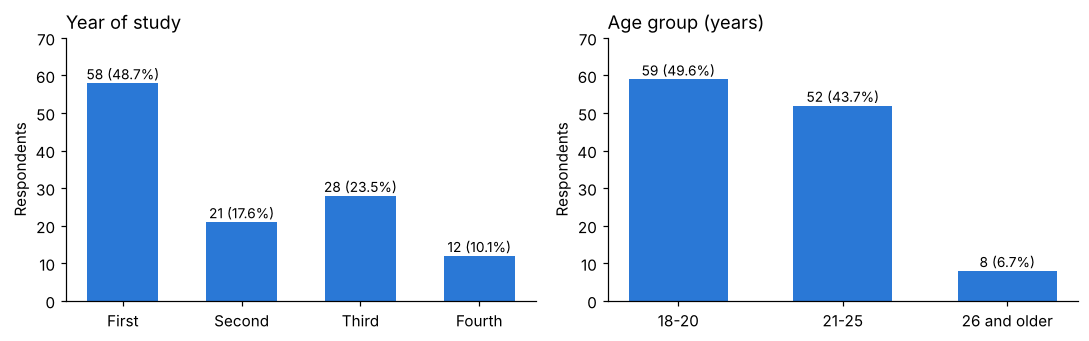

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, order, title in [(axes[0], "year_c", ["First", "Second", "Third", "Fourth"], "Year of study"),
                              (axes[1], "age_c", ["18-20", "21-25", "26 and older"], "Age group (years)")]:
    s = df[col].value_counts().reindex(order)
    bars = ax.bar(s.index, s.values, color=BLUE, width=.6)
    for b, v in zip(bars, s.values):
        ax.text(b.get_x() + b.get_width()/2, v + 1, f"{v} ({100*v/len(df):.1f}%)", ha="center", fontsize=9)
    ax.set_title(title, loc="left"); ax.set_ylabel("Respondents"); ax.set_ylim(0, 70)
plt.tight_layout(); plt.show()

## 6. Reliability (Tables 4.3 and 4.4)
Cronbach's α with 95% CI, McDonald's ω (one-factor), mean inter-item correlation, corrected item–total correlations and α-if-item-deleted. Benchmark: α ≥ .70.

In [10]:
def item_analysis(cols):
    d = df[cols].dropna()
    a, ci = pg.cronbach_alpha(d)
    corr = d.corr().values
    fa = FactorAnalyzer(n_factors=1, rotation=None, method="minres"); fa.fit(d)
    l = fa.loadings_.ravel(); u = fa.get_uniquenesses()
    omega = l.sum()**2 / (l.sum()**2 + u.sum())
    items = []
    for c in cols:
        rest = d.drop(columns=c).mean(axis=1)
        aid = pg.cronbach_alpha(d.drop(columns=c))[0] if len(cols) > 2 else np.nan
        items.append({"item": c, "M": d[c].mean(), "SD": d[c].std(), "corrected item-total r": np.corrcoef(d[c], rest)[0, 1], "alpha if deleted": aid})
    summary = {"items": len(cols), "n": len(d), "alpha": a, "alpha 95% CI": f"[{ci[0]:.2f}, {ci[1]:.2f}]", "omega": abs(omega),
               "mean inter-item r": corr[np.triu_indices(len(cols), 1)].mean(),
               "item-total r range": f"{min(i['corrected item-total r'] for i in items):.2f} – {max(i['corrected item-total r'] for i in items):.2f}"}
    return summary, pd.DataFrame(items).set_index("item")

rel_sets = {"Institutional factors": B, "Academic engagement": C, "Student satisfaction": D, "Retention intention": Er,
            "Retention intention without E1": ["E2", "E3r", "E4r", "E5"], "Retention intention, positive items (E1, E2, E5)": ["E1", "E2", "E5"]}
rel_summary, rel_items = {}, {}
for lab, cols in rel_sets.items():
    rel_summary[lab], rel_items[lab] = item_analysis(cols)
pd.DataFrame(rel_summary).T.round(3)

,items,n,alpha,alpha 95% CI,omega,mean inter-item r,item-total r range
Institutional factors,12,116,0.887364,"[0.85, 0.92]",0.889607,0.397734,0.45 – 0.76
Academic engagement,8,118,0.804848,"[0.75, 0.85]",0.81067,0.345547,0.40 – 0.60
Student satisfaction,10,116,0.916455,"[0.89, 0.94]",0.921325,0.531752,0.44 – 0.84
Retention intention,5,119,0.563902,"[0.43, 0.68]",0.659851,0.245301,0.24 – 0.51
Retention intention without E1,4,119,0.575411,"[0.44, 0.69]",0.673903,0.291558,0.28 – 0.46
"Retention intention, positive items (E1, E2, E5)",3,119,0.604848,"[0.46, 0.71]",0.763172,0.427665,0.27 – 0.60


In [11]:
# Item analysis for each predictor scale
for lab in ["Institutional factors", "Academic engagement", "Student satisfaction"]:
    print(lab); display(rel_items[lab].round(3))

Institutional factors


,M,SD,corrected item-total r,alpha if deleted
item,,,,
B1,3.828,0.998,0.636,0.876
B2,4.112,0.892,0.488,0.884
B3,4.155,0.938,0.616,0.877
B4,3.569,1.260,0.648,0.875
B5,4.216,0.842,0.499,0.883
B6,4.060,0.897,0.625,0.877
B7,3.922,1.064,0.664,0.874
B8,3.319,1.154,0.451,0.887
B9,3.741,0.988,0.569,0.880


Academic engagement


,M,SD,corrected item-total r,alpha if deleted
item,,,,
C1,3.831,1.150,0.512,0.784
C2,3.763,1.076,0.589,0.772
C3,4.568,0.790,0.499,0.789
C4,3.695,1.223,0.585,0.772
C5,4.144,1.015,0.430,0.795
C6,3.576,1.423,0.562,0.779
C7,3.720,1.003,0.603,0.771
C8,4.000,1.029,0.402,0.799


Student satisfaction


,M,SD,corrected item-total r,alpha if deleted
item,,,,
D1,3.905,1.013,0.810,0.902
D2,3.741,1.180,0.842,0.899
D3,3.422,1.231,0.663,0.910
D4,3.431,1.239,0.650,0.911
D5,3.767,1.197,0.680,0.909
D6,3.629,1.034,0.723,0.906
D7,3.871,1.131,0.736,0.905
D8,3.750,1.118,0.443,0.922
D9,3.897,1.008,0.660,0.910


In [12]:
# Retention-intention scale in detail (Table 4.4)
print("Raw inter-item correlations of E1–E5 (before reverse-scoring):")
display(df[E].corr().round(2))
rel_items["Retention intention"].round(3)

Raw inter-item correlations of E1–E5 (before reverse-scoring):


,E1,E2,E3,E4,E5
E1,1.00,0.30,-0.06,-0.14,0.20
E2,0.30,1.00,-0.22,-0.15,0.78
E3,-0.06,-0.22,1.00,0.35,-0.19
E4,-0.14,-0.15,0.35,1.00,-0.06
E5,0.20,0.78,-0.19,-0.06,1.00


,M,SD,corrected item-total r,alpha if deleted
item,,,,
E1,3.790,1.512,0.235,0.575
E2,4.479,0.955,0.511,0.432
E3r,3.714,1.445,0.305,0.524
E4r,3.555,1.364,0.286,0.533
E5,4.630,0.842,0.419,0.485


### 6.1 Why E1 behaves differently: it depends on year of study
E1 asks about continuing *in the next academic year*. Students completing their qualification cannot do so, so their disagreement reflects completion, not an intention to leave.

In [13]:
yrs = ["First", "Second", "Third", "Fourth"]
e1 = pd.DataFrame({g: {"n": (df.year_c == g).sum(),
                       "E1 mean": df.loc[df.year_c == g, "E1"].mean(),
                       "% disagree with E1": 100 * (df.loc[df.year_c == g, "E1"] <= 2).mean(),
                       "E2 mean": df.loc[df.year_c == g, "E2"].mean(),
                       "E5 mean": df.loc[df.year_c == g, "E5"].mean()} for g in yrs}).T.round(2)
kw = stats.kruskal(*[df.loc[df.year_c == g, "E1"].dropna() for g in yrs])
print(f"Kruskal–Wallis test of E1 across years: H = {kw.statistic:.2f}, p {fmt_p(kw.pvalue)}")
e1

Kruskal–Wallis test of E1 across years: H = 43.23, p < .001


,n,E1 mean,% disagree with E1,E2 mean,E5 mean
First,58.0,4.45,8.62,4.38,4.45
Second,21.0,4.38,4.76,4.67,4.90
Third,28.0,2.93,42.86,4.39,4.68
Fourth,12.0,1.58,75.00,4.83,4.92


## 7. Factor structure (Table 4.5) and discriminant validity
KMO and Bartlett's test check factorability. The number of factors is chosen by **parallel analysis** (observed eigenvalues vs 95th percentile of eigenvalues from 500 random data sets). Extraction: principal axis factoring, promax rotation.

In [14]:
def parallel_analysis(d, reps=500, seed=2026):
    ev = np.linalg.eigvalsh(d.corr().values)[::-1]
    rng = np.random.default_rng(seed)
    rand = np.array([np.linalg.eigvalsh(np.corrcoef(rng.standard_normal(d.shape), rowvar=False))[::-1] for _ in range(reps)])
    thr = np.percentile(rand, 95, axis=0)
    nfac = int(np.argmax(ev < thr)) if (ev < thr).any() else len(ev)
    return ev, thr, nfac

efa_rows = {}
for lab, cols in [("Institutional factors (B1–B12)", B), ("Academic engagement (C1–C8)", C), ("Student satisfaction (D1–D10)", D),
                  ("Retention intention (E1–E5)", Er), ("All predictor items (B, C, D)", B + C + D)]:
    d = df[cols].dropna()
    chi, p = calculate_bartlett_sphericity(d)
    _, kmo = calculate_kmo(d)
    ev, thr, nfac = parallel_analysis(d)
    efa_rows[lab] = {"n": len(d), "KMO": round(kmo, 2), "Bartlett": f"χ²({len(cols)*(len(cols)-1)//2}) = {chi:.2f}, p {fmt_p(p)}",
                     "first two eigenvalues": f"{ev[0]:.2f}, {ev[1]:.2f}", "eigenvalues > 1": int((ev > 1).sum()),
                     "factors (parallel analysis)": nfac, "% variance, first component": round(100 * ev[0] / len(cols), 1)}
pd.DataFrame(efa_rows).T

,n,KMO,Bartlett,first two eigenvalues,eigenvalues > 1,factors (parallel analysis),"% variance, first component"
Institutional factors (B1–B12),116,0.89,"χ²(66) = 556.29, p < .001","5.44, 1.07",2,1,45.4
Academic engagement (C1–C8),118,0.82,"χ²(28) = 250.76, p < .001","3.45, 1.05",2,1,43.1
Student satisfaction (D1–D10),116,0.9,"χ²(45) = 727.19, p < .001","5.87, 1.00",2,1,58.7
Retention intention (E1–E5),119,0.56,"χ²(10) = 143.96, p < .001","2.08, 1.19",2,2,41.6
"All predictor items (B, C, D)",112,0.9,"χ²(435) = 1955.99, p < .001","11.58, 3.06",6,2,38.6


In [15]:
# Single-factor loadings for each scale (absolute values; signs are arbitrary in factor analysis)
load = {}
for lab, cols in [("IF", B), ("AE", C), ("SS", D)]:
    fa = FactorAnalyzer(n_factors=1, rotation=None, method="principal"); fa.fit(df[cols].dropna())
    load[lab] = pd.Series(np.abs(fa.loadings_.ravel()), index=cols)
print("Lowest single-factor loading per scale:", {k: round(v.min(), 3) for k, v in load.items()})

# Two-factor solution for retention intention
fa = FactorAnalyzer(n_factors=2, rotation="promax", method="principal"); fa.fit(df[Er].dropna())
pd.DataFrame(fa.loadings_, index=Er, columns=["Factor 1 (commitment)", "Factor 2 (doubt)"]).round(2)

Lowest single-factor loading per scale: {'IF': np.float64(0.527), 'AE': np.float64(0.525), 'SS': np.float64(0.525)}


,Factor 1 (commitment),Factor 2 (doubt)
E1,0.46,0.07
E2,0.93,-0.01
E3r,0.07,0.78
E4r,-0.08,0.86
E5,0.93,-0.11


In [16]:
# All 30 predictor items together: are IF, AE and SS empirically distinct?
dpred = df[B + C + D].dropna()
fa = FactorAnalyzer(n_factors=2, rotation="promax", method="principal"); fa.fit(dpred)
L = pd.DataFrame(fa.loadings_, index=B + C + D, columns=["F1", "F2"]).round(2)
L["scale"] = [c[0] for c in L.index]
print("IF and SS items share Factor 1; AE items load on Factor 2 (C5 and C8 cross-load):")
display(L.style.background_gradient(cmap="Blues", subset=["F1", "F2"], vmin=0, vmax=1))

# Harman's single-factor test for common-method variance
d = df[ALL].dropna(); ev = np.linalg.eigvalsh(d.corr().values)[::-1]
print(f"Harman's test: first unrotated factor explains {100*ev[0]/len(ALL):.1f}% of variance in all 35 items (n = {len(d)})")

IF and SS items share Factor 1; AE items load on Factor 2 (C5 and C8 cross-load):


,F1,F2,scale
B1,0.700000,0.100000,B
B2,0.610000,-0.190000,B
B3,0.650000,-0.120000,B
B4,0.770000,-0.090000,B
B5,0.590000,-0.080000,B
B6,0.630000,-0.010000,B
B7,0.760000,-0.080000,B
B8,0.480000,-0.010000,B
B9,0.670000,-0.170000,B
B10,0.800000,-0.050000,B


Harman's test: first unrotated factor explains 34.6% of variance in all 35 items (n = 112)


## 8. Descriptive statistics (Table 4.6, Figures 4.2–4.3)

In [17]:
desc = {}
for k in ["IF", "AE", "SS", "RI", "RI4"]:
    s = df[k].dropna(); se = s.std() / np.sqrt(len(s)); t = stats.t.ppf(.975, len(s) - 1)
    tt = stats.ttest_1samp(s, 3.0)
    desc[names[k]] = {"n": len(s), "M": s.mean(), "SD": s.std(), "95% CI": f"[{s.mean()-t*se:.2f}, {s.mean()+t*se:.2f}]",
                      "Mdn": s.median(), "skew": stats.skew(s), "kurtosis": stats.kurtosis(s), "% above 3": 100 * (s > 3).mean(),
                      "% ≥ 4": 100 * (s >= 4).mean(), "Shapiro–Wilk p": fmt_p(stats.shapiro(s).pvalue),
                      "t vs 3": f"t({len(s)-1}) = {tt.statistic:.2f}, p {fmt_p(tt.pvalue)}", "d vs 3": (s.mean() - 3) / s.std()}
pd.DataFrame(desc).T.round(2)

,n,M,SD,95% CI,Mdn,skew,kurtosis,% above 3,% ≥ 4,Shapiro–Wilk p,t vs 3,d vs 3
Institutional factors,118,3.838855,0.683675,"[3.71, 3.96]",3.871212,-0.265454,-0.582613,86.440678,46.610169,.047,"t(117) = 13.33, p < .001",1.226978
Academic engagement,119,3.909214,0.714186,"[3.78, 4.04]",3.875,-0.741971,1.48053,89.915966,48.739496,< .001,"t(118) = 13.89, p < .001",1.273077
Student satisfaction,119,3.748366,0.828659,"[3.60, 3.90]",3.8,-0.294721,-0.668144,78.151261,42.857143,.007,"t(118) = 9.85, p < .001",0.903105
Retention intention,119,4.033613,0.756584,"[3.90, 4.17]",4.0,-0.604296,0.121163,87.394958,56.302521,< .001,"t(118) = 14.90, p < .001",1.366158
Retention intention (E1 removed),119,4.094538,0.782483,"[3.95, 4.24]",4.25,-0.663031,-0.112565,85.714286,63.865546,< .001,"t(118) = 15.26, p < .001",1.398801


In [18]:
# Item-level descriptives (Annexure Table F.1)
it = pd.DataFrame({c: {"statement": item_text[c], "n": df[c].notna().sum(), "M": df[c].mean(), "SD": df[c].std(),
                       "% disagree (1–2)": 100 * (df[c].dropna() <= 2).mean(), "% neutral": 100 * (df[c].dropna() == 3).mean(),
                       "% agree (4–5)": 100 * (df[c].dropna() >= 4).mean()} for c in ALL}).T
for col in ["M", "SD", "% disagree (1–2)", "% neutral", "% agree (4–5)"]:
    it[col] = it[col].astype(float).round(2 if col in ("M", "SD") else 1)
it

,statement,n,M,SD,% disagree (1–2),% neutral,% agree (4–5)
B1,The quality of teaching at this institution meets my expectations.,119,3.84,1.00,8.4,28.6,63.0
B2,Academic staff are accessible and willing to assist students.,119,4.12,0.88,5.0,18.5,76.5
B3,"The institution provides adequate academic support services (tutoring, writing centre,...",119,4.17,0.93,6.7,16.0,77.3
B4,I am satisfied with the administrative services provided by the institution.,119,3.61,1.26,21.8,21.0,57.1
B5,"The institution's physical learning environment (classrooms, facilities) is adequate.",118,4.22,0.84,2.5,18.6,78.8
B6,The institution provides sufficient digital learning resources and technology support.,118,4.08,0.90,5.1,21.2,73.7
B7,The institution communicates clearly and timeously about important academic matters.,118,3.94,1.06,12.7,18.6,68.6
B8,The financial payment options offered by the institution are flexible and manageable.,117,3.30,1.17,18.8,42.7,38.5
B9,Career guidance and placement services are available and useful.,119,3.74,0.99,7.6,34.5,58.0
B10,I feel that the institution values my well-being as a student.,119,3.54,1.13,14.3,37.0,48.7


In [19]:
# Doubt signals among respondents
both = df[["E3", "E4"]].notna().all(axis=1)
either = ((df["E3"] >= 4) | (df["E4"] >= 4))
print(f"Agreed they had considered withdrawing (E3): {100*(df.E3 >= 4).mean():.1f}%")
print(f"Agreed they would choose a different institution (E4): {100*(df.E4 >= 4).mean():.1f}%")
print(f"Agreed with at least one of E3/E4: {either.sum()} of {both.sum()} ({100*either.sum()/both.sum():.1f}%)")
print(f"Retention-intention composite below 3: {(df.RI < 3).sum()} ({100*(df.RI < 3).mean():.1f}%)")

Agreed they had considered withdrawing (E3): 23.5%
Agreed they would choose a different institution (E4): 21.0%
Agreed with at least one of E3/E4: 43 of 119 (36.1%)
Retention-intention composite below 3: 9 (7.6%)


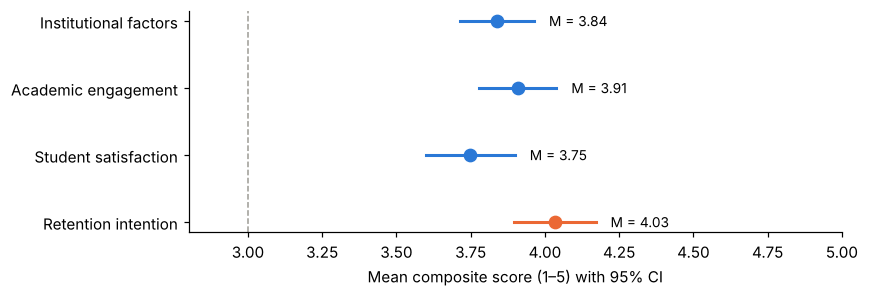

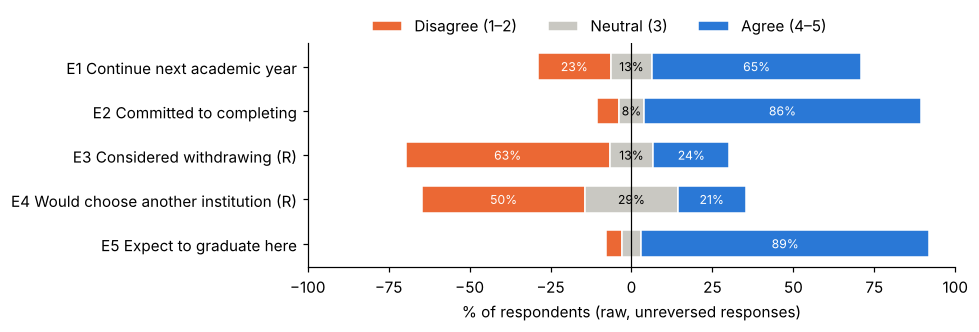

In [20]:
fig, ax = plt.subplots(figsize=(8, 2.8))
keys = ["RI", "SS", "AE", "IF"]
for i, k in enumerate(keys):
    s = df[k].dropna(); se = s.std() / np.sqrt(len(s)); t = stats.t.ppf(.975, len(s) - 1)
    c = ORANGE if k == "RI" else BLUE
    ax.plot([s.mean() - t*se, s.mean() + t*se], [i, i], color=c, lw=2); ax.plot(s.mean(), i, "o", color=c, ms=8)
    ax.text(s.mean() + t*se + .05, i, f"M = {s.mean():.2f}", va="center", fontsize=9)
ax.axvline(3, color=GREY, ls="--", lw=1)
ax.set_yticks(range(4)); ax.set_yticklabels([names[k] for k in keys]); ax.set_xlim(2.8, 5)
ax.set_xlabel("Mean composite score (1–5) with 95% CI"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
labs = {"E1": "E1 Continue next academic year", "E2": "E2 Committed to completing", "E3": "E3 Considered withdrawing (R)",
        "E4": "E4 Would choose another institution (R)", "E5": "E5 Expect to graduate here"}
for i, e in enumerate(E[::-1]):
    s = df[e].dropna(); dis, neu, agr = 100*(s <= 2).mean(), 100*(s == 3).mean(), 100*(s >= 4).mean()
    left = -dis - neu/2
    for w, c, lab in [(dis, ORANGE, "Disagree (1–2)"), (neu, "#c9c8c2", "Neutral (3)"), (agr, BLUE, "Agree (4–5)")]:
        ax.barh(i, w, left=left, color=c, edgecolor="white", height=.6, label=lab if i == 0 else None)
        if w >= 7: ax.text(left + w/2, i, f"{w:.0f}%", ha="center", va="center", fontsize=8, color="white" if c != "#c9c8c2" else "black")
        left += w
ax.axvline(0, color="black", lw=.8); ax.set_yticks(range(5)); ax.set_yticklabels([labs[e] for e in E[::-1]])
ax.set_xlim(-100, 100); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.45, 1.18), frameon=False)
ax.set_xlabel("% of respondents (raw, unreversed responses)"); plt.tight_layout(); plt.show()

## 9. Correlations (Table 4.7, Figure 4.4)
Pearson r with 95% CI and exact p, plus Spearman ρ (composites are not normally distributed). Bonferroni correction for six tests.

In [21]:
V = ["IF", "AE", "SS", "RI"]
cc = df[V].dropna()
rows = []
for a, b in itertools.combinations(V, 2):
    res = stats.pearsonr(cc[a], cc[b]); ci = res.confidence_interval(); rho = stats.spearmanr(cc[a], cc[b])
    rows.append({"pair": f"{names[a]} – {names[b]}", "r": res.statistic, "95% CI": f"[{ci.low:.2f}, {ci.high:.2f}]",
                 "p": fmt_p(res.pvalue), "Bonferroni p": fmt_p(min(1, res.pvalue * 6)), "Spearman ρ": rho.statistic, "ρ p": fmt_p(rho.pvalue)})
print(f"n = {len(cc)} (listwise)")
pd.DataFrame(rows).round(3)

n = 118 (listwise)


,pair,r,95% CI,p,Bonferroni p,Spearman ρ,ρ p
0,Institutional factors – Academic engagement,0.335,"[0.16, 0.49]",< .001,.001,0.356,< .001
1,Institutional factors – Student satisfaction,0.811,"[0.74, 0.86]",< .001,< .001,0.803,< .001
2,Institutional factors – Retention intention,0.341,"[0.17, 0.49]",< .001,< .001,0.365,< .001
3,Academic engagement – Student satisfaction,0.483,"[0.33, 0.61]",< .001,< .001,0.494,< .001
4,Academic engagement – Retention intention,0.263,"[0.09, 0.42]",.004,.024,0.221,.016
5,Student satisfaction – Retention intention,0.460,"[0.30, 0.59]",< .001,< .001,0.469,< .001


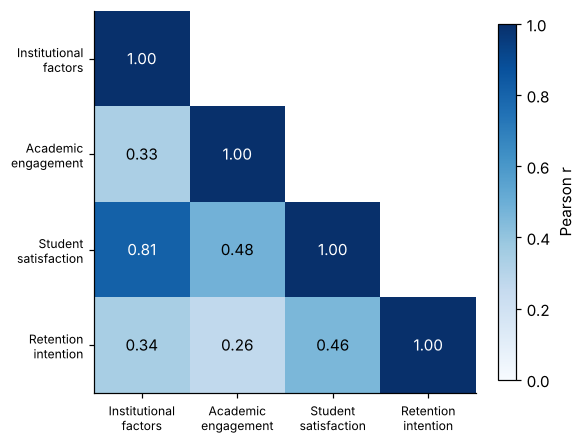

In [22]:
cm = cc.corr()
fig, ax = plt.subplots(figsize=(5.2, 4.2))
mask = np.triu(np.ones_like(cm, dtype=bool), 1)
im = ax.imshow(np.where(mask, np.nan, cm), cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(i + 1):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", color="white" if cm.iloc[i, j] > .55 else "black")
short = ["Institutional\nfactors", "Academic\nengagement", "Student\nsatisfaction", "Retention\nintention"]
ax.set_xticks(range(4)); ax.set_xticklabels(short, fontsize=8); ax.set_yticks(range(4)); ax.set_yticklabels(short, fontsize=8)
fig.colorbar(im, ax=ax, fraction=.04, label="Pearson r"); plt.tight_layout(); plt.show()

## 10. Multiple regression — Model 1 (Tables 4.8 and 4.9)
OLS regression of retention intention on the three composites. The helper below returns coefficients (B, SE, 95% CI, standardised β), HC3 robust SEs, VIF/tolerance and the assumption checks.

In [23]:
def fit_report(formula, data):
    m = smf.ols(formula, data=data).fit()
    mr = smf.ols(formula, data=data).fit(cov_type="HC3")
    y, X, xn = m.model.endog, m.model.exog, m.model.exog_names
    ci = m.conf_int()
    coefs = pd.DataFrame({
        "B": m.params, "SE": m.bse, "CI low": ci[0], "CI high": ci[1],
        "β": [np.nan if nm == "Intercept" else m.params[nm] * X[:, i].std(ddof=1) / y.std(ddof=1) for i, nm in enumerate(xn)],
        "t": m.tvalues, "p": m.pvalues, "HC3 SE": mr.bse, "HC3 p": mr.pvalues,
        "VIF": [np.nan if nm == "Intercept" else variance_inflation_factor(X, i) for i, nm in enumerate(xn)]})
    coefs["tolerance"] = 1 / coefs["VIF"]
    infl = m.get_influence(); cooks = infl.cooks_distance[0]; sres = infl.resid_studentized_external
    d2 = data.copy(); d2["_fit2"] = m.fittedvalues ** 2
    reset_p = smf.ols(formula + " + _fit2", data=d2).fit().pvalues["_fit2"]
    bp = het_breuschpagan(m.resid, X); sw = stats.shapiro(m.resid)
    fit = {"n": int(m.nobs), "F": f"F({int(m.df_model)}, {int(m.df_resid)}) = {m.fvalue:.2f}, p {fmt_p(m.f_pvalue)}",
           "R²": round(m.rsquared, 3), "adj. R²": round(m.rsquared_adj, 3), "f²": round(m.rsquared / (1 - m.rsquared), 3)}
    diag = {"RESET p (linearity)": fmt_p(reset_p), "Durbin–Watson": round(durbin_watson(m.resid), 2),
            "Breusch–Pagan": f"LM = {bp[0]:.2f}, p = {fmt_p(bp[1])}",
            "Shapiro–Wilk (residuals)": f"W = {sw.statistic:.3f}, p = {fmt_p(sw.pvalue)}", "residual skew": round(stats.skew(m.resid), 2),
            "condition number": round(m.condition_number, 1), "max Cook's D": round(cooks.max(), 3),
            "cases Cook's D > 4/n": int((cooks > 4 / len(y)).sum()), "cases |studentised residual| > 3": int((np.abs(sres) > 3).sum())}
    return m, coefs, fit, diag, cooks

d1 = df[["IF", "AE", "SS", "RI", "ID", "duration_s"]].dropna().copy()
m1, coefs1, fit1, diag1, cooks1 = fit_report("RI ~ IF + AE + SS", d1)
print(fit1)
coefs1.round(3)

{'n': 118, 'F': 'F(3, 114) = 10.51, p < .001', 'R²': np.float64(0.217), 'adj. R²': np.float64(0.196), 'f²': np.float64(0.276)}


,B,SE,CI low,CI high,β,t,p,HC3 SE,HC3 p,VIF,tolerance
Intercept,2.491,0.440,1.619,3.363,NaN,5.659,0.000,0.557,0.000,NaN,NaN
IF,-0.096,0.157,-0.407,0.215,-0.087,-0.609,0.544,0.149,0.521,2.954,0.339
AE,0.049,0.100,-0.149,0.248,0.047,0.493,0.623,0.159,0.757,1.321,0.757
SS,0.461,0.139,0.185,0.737,0.508,3.313,0.001,0.124,0.000,3.421,0.292


In [24]:
# Assumption checks (Table 4.9)
pd.Series(diag1, name="Model 1").to_frame()

,Model 1
RESET p (linearity),.436
Durbin–Watson,1.95
Breusch–Pagan,"LM = 5.78, p = .123"
Shapiro–Wilk (residuals),"W = 0.958, p = .001"
residual skew,-0.71
condition number,49.7
max Cook's D,0.506
cases Cook's D > 4/n,6
cases |studentised residual| > 3,1


In [25]:
# Percentile bootstrap 95% CIs (2 000 resamples)
rng = np.random.default_rng(42)
bs = {"IF": [], "AE": [], "SS": [], "R2": []}
for _ in range(2000):
    s = d1.sample(len(d1), replace=True, random_state=int(rng.integers(1e9)))
    mm = smf.ols("RI ~ IF + AE + SS", data=s).fit()
    for p_ in ["IF", "AE", "SS"]: bs[p_].append(mm.params[p_])
    bs["R2"].append(mm.rsquared)
pd.DataFrame({k: {"2.5%": np.percentile(v, 2.5), "97.5%": np.percentile(v, 97.5)} for k, v in bs.items()}).T.round(3)

,2.5%,97.5%
IF,-0.371,0.229
AE,-0.211,0.310
SS,0.192,0.694
R2,0.124,0.370


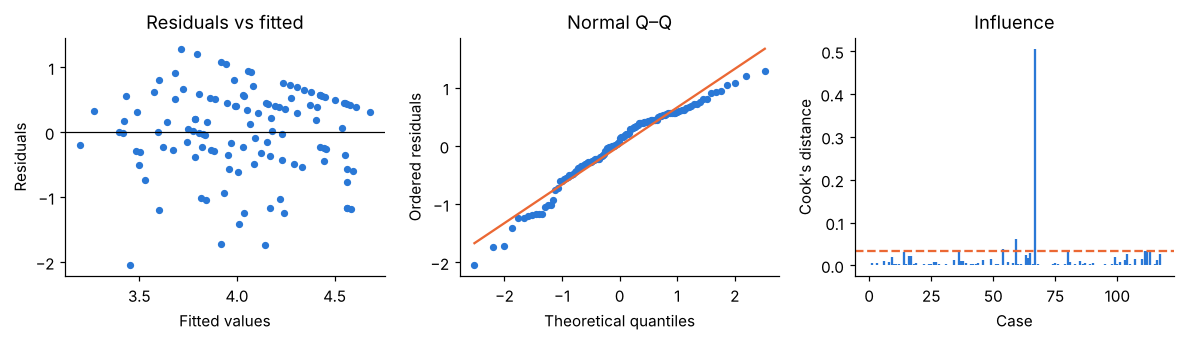

In [26]:
# Diagnostic plots (Annexure Figure F.1)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].scatter(m1.fittedvalues, m1.resid, s=14, color=BLUE); axes[0].axhline(0, color="black", lw=.8)
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs fitted")
(osm, osr), (sl, ic, _) = stats.probplot(m1.resid, dist="norm")
axes[1].scatter(osm, osr, s=14, color=BLUE); axes[1].plot(osm, sl * osm + ic, color=ORANGE)
axes[1].set(xlabel="Theoretical quantiles", ylabel="Ordered residuals", title="Normal Q–Q")
axes[2].vlines(range(len(cooks1)), 0, cooks1, color=BLUE); axes[2].axhline(4 / len(cooks1), color=ORANGE, ls="--")
axes[2].set(xlabel="Case", ylabel="Cook's distance", title="Influence")
plt.tight_layout(); plt.show()

## 11. Statistical power (Section 3.5.3)
Sensitivity analysis: the smallest effect size (Cohen's f²) detectable with 80% power at α = .05, given the achieved sample.

In [27]:
def power_f2(f2, n, u, alpha=.05):
    v = n - u - 1
    return 1 - stats.ncf.cdf(stats.f.ppf(1 - alpha, u, v), u, v, f2 * n)

def min_f2(n, u, target=.8):
    lo, hi = 1e-4, 2
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if power_f2(mid, n, u) < target else (lo, mid)
    return hi

n1 = int(m1.nobs)
print(f"n = {n1}: minimum detectable f² (overall model, 3 predictors) = {min_f2(n1, 3):.3f}; "
      f"single coefficient = {min_f2(n1, 1):.3f}")

n = 118: minimum detectable f² (overall model, 3 predictors) = 0.096; single coefficient = 0.068


## 12. Relative importance: dominance analysis and unique vs shared variance (Figure 4.5)
Because IF and SS correlate at .81, individual coefficients are imprecise. Dominance analysis averages each predictor's increase in R² across all subsets of the other predictors.

In [28]:
preds = ["IF", "AE", "SS"]
sub_r2 = {(): 0.0}
for r_ in range(1, 4):
    for combo in itertools.combinations(preds, r_):
        sub_r2[combo] = smf.ols("RI ~ " + " + ".join(combo), data=d1).fit().rsquared
full = sub_r2[tuple(preds)]

dom = {}
for p_ in preds:
    others = [q for q in preds if q != p_]
    levels = []
    for size in range(3):
        incs = [sub_r2[tuple(sorted(c + (p_,), key=preds.index))] - sub_r2[tuple(sorted(c, key=preds.index))]
                for c in itertools.combinations(others, size)]
        levels.append(np.mean(incs))
    dom[names[p_]] = {"alone": levels[0], "given 1 other": levels[1], "given both others": levels[2],
                      "general dominance": np.mean(levels), "% of R²": 100 * np.mean(levels) / full}
print(f"Full-model R² = {full:.4f}")
print("R² of every subset:", {"+".join(k): round(v, 4) for k, v in sub_r2.items() if k})
display(pd.DataFrame(dom).T.round(4))

unique = {p_: full - sub_r2[tuple(q for q in preds if q != p_)] for p_ in preds}
unique["shared"] = full - sum(unique.values())
pd.Series({("Unique: " + names[k]) if k != "shared" else "Shared by predictors": v for k, v in unique.items()}, name="variance").round(4).to_frame()

Full-model R² = 0.2166
R² of every subset: {'IF': np.float64(0.1161), 'AE': np.float64(0.0693), 'SS': np.float64(0.2119), 'IF+AE': np.float64(0.1412), 'IF+SS': np.float64(0.2149), 'AE+SS': np.float64(0.214), 'IF+AE+SS': np.float64(0.2166)}


,alone,given 1 other,given both others,general dominance,% of R²
Institutional factors,0.1161,0.0375,0.0025,0.0520,24.0258
Academic engagement,0.0693,0.0136,0.0017,0.0282,13.0183
Student satisfaction,0.2119,0.1218,0.0754,0.1364,62.9558


,variance
Unique: Institutional factors,0.0025
Unique: Academic engagement,0.0017
Unique: Student satisfaction,0.0754
Shared by predictors,0.1370


## 13. Robustness checks (Table 4.10) and Model 2 with controls (Table 4.11)

In [29]:
straight_ids = df.loc[df[ALL].std(axis=1) == 0, "ID"].tolist()
specs = {
    "Model 1 as specified": ("RI ~ IF + AE + SS", d1),
    "Excluding completions < 60 s": ("RI ~ IF + AE + SS", d1[d1.duration_s >= 60]),
    "Excluding straight-liners": ("RI ~ IF + AE + SS", d1[~d1.ID.isin(straight_ids)]),
    "Excluding Cook's D > 4/n": ("RI ~ IF + AE + SS", d1[cooks1 <= 4 / len(d1)]),
    "Rank-transformed variables": ("RI ~ IF + AE + SS", d1[["IF", "AE", "SS", "RI"]].rank()),
    "Outcome without E1": ("RI4 ~ IF + AE + SS", df[["IF", "AE", "SS", "RI4"]].dropna()),
    "Outcome = E1, E2, E5 only": ("RI3 ~ IF + AE + SS", df[["IF", "AE", "SS", "RI3"]].dropna()),
}
rows = {}
for lab, (f, d) in specs.items():
    _, cf, ft, _, _ = fit_report(f, d)
    rows[lab] = {"n": ft["n"], "R²": ft["R²"], "adj. R²": ft["adj. R²"], **{f"{p_} β (p)": f"{cf.loc[p_, 'β']:.2f} ({fmt_p(cf.loc[p_, 'p'])})" for p_ in preds}}
pd.DataFrame(rows).T

,n,R²,adj. R²,IF β (p),AE β (p),SS β (p)
Model 1 as specified,118,0.217,0.196,-0.09 (.544),0.05 (.623),0.51 (.001)
Excluding completions < 60 s,116,0.214,0.193,-0.08 (.567),0.04 (.705),0.51 (.001)
Excluding straight-liners,116,0.252,0.232,-0.04 (.768),0.08 (.398),0.49 (.001)
Excluding Cook's D > 4/n,112,0.256,0.235,-0.12 (.396),0.04 (.699),0.58 (< .001)
Rank-transformed variables,118,0.221,0.2,-0.03 (.805),-0.02 (.860),0.51 (< .001)
Outcome without E1,118,0.156,0.134,-0.18 (.231),0.11 (.252),0.45 (.005)
"Outcome = E1, E2, E5 only",118,0.204,0.183,0.00 (.999),0.05 (.595),0.42 (.007)


In [30]:
# Model 2: hierarchical regression with demographic controls
d2 = df[["IF", "AE", "SS", "RI", "year_c", "employed", "gender", "funding_c", "age_c"]].dropna().copy()
d2 = d2[d2.gender.isin(["Female", "Male"])]
d2["female"] = (d2.gender == "Female").astype(int)
d2["emp"] = (d2.employed == "Employed").astype(int)
d2["selffund"] = (d2.funding_c == "Personal/family funds").astype(int)
for y_, nm in [("Second", "yr2"), ("Third", "yr3"), ("Fourth", "yr4")]: d2[nm] = (d2.year_c == y_).astype(int)
d2["age21"] = (d2.age_c == "21-25").astype(int); d2["age26"] = (d2.age_c == "26 and older").astype(int)
controls = "female + emp + selffund + yr2 + yr3 + yr4 + age21 + age26"

mc, cfc, ftc, _, _ = fit_report(f"RI ~ {controls}", d2)
m2, cf2, ft2, _, _ = fit_report(f"RI ~ {controls} + IF + AE + SS", d2)
fchg = ((m2.rsquared - mc.rsquared) / 3) / ((1 - m2.rsquared) / m2.df_resid)
print("Step 1 (controls only):", ftc)
print("Step 2 (+ predictors): ", ft2)
print(f"ΔR² = {m2.rsquared - mc.rsquared:.3f}, F(3, {int(m2.df_resid)}) = {fchg:.2f}, p {fmt_p(1 - stats.f.cdf(fchg, 3, m2.df_resid))}")
cf2[["B", "CI low", "CI high", "β", "p", "VIF"]].round(3)

Step 1 (controls only): {'n': 115, 'F': 'F(8, 106) = 1.52, p .158', 'R²': np.float64(0.103), 'adj. R²': np.float64(0.035), 'f²': np.float64(0.115)}
Step 2 (+ predictors):  {'n': 115, 'F': 'F(11, 103) = 4.19, p < .001', 'R²': np.float64(0.309), 'adj. R²': np.float64(0.235), 'f²': np.float64(0.447)}
ΔR² = 0.206, F(3, 103) = 10.24, p < .001


,B,CI low,CI high,β,p,VIF
Intercept,3.121,2.122,4.121,NaN,0.000,NaN
female,-0.393,-0.679,-0.108,-0.234,0.007,1.098
emp,-0.005,-0.373,0.362,-0.003,0.977,1.196
selffund,-0.273,-0.683,0.136,-0.115,0.189,1.129
yr2,0.391,0.026,0.756,0.197,0.036,1.284
yr3,0.068,-0.327,0.463,0.038,0.734,1.836
yr4,0.094,-0.444,0.633,0.038,0.729,1.818
age21,-0.098,-0.412,0.216,-0.065,0.537,1.626
age26,-0.520,-1.136,0.096,-0.176,0.097,1.648
IF,-0.165,-0.486,0.156,-0.147,0.311,3.123


## 14. Group comparisons: employment, gender, funding (Table 4.12)
Welch's t-test (no equal-variance assumption), Hedges' g with 95% CI, Mann–Whitney U as a non-parametric check, and the minimum detectable effect (d) at 80% power.

In [31]:
def two_group(var, groupcol, g1, g2):
    a = df.loc[df[groupcol] == g1, var].dropna(); b = df.loc[df[groupcol] == g2, var].dropna()
    w = stats.ttest_ind(a, b, equal_var=False)
    va, vb = a.var() / len(a), b.var() / len(b)
    wdf = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    d = (a.mean() - b.mean()) / sp
    g = d * (1 - 3 / (4 * (len(a) + len(b)) - 9))
    se_d = np.sqrt((len(a) + len(b)) / (len(a) * len(b)) + d * d / (2 * (len(a) + len(b))))
    mdd = (stats.norm.ppf(.975) + stats.norm.ppf(.8)) * np.sqrt(1 / len(a) + 1 / len(b))
    return {f"{g1}: M (SD), n": f"{a.mean():.2f} ({a.std():.2f}), {len(a)}", f"other: M (SD), n": f"{b.mean():.2f} ({b.std():.2f}), {len(b)} [{g2}]",
            "Welch t": f"t({wdf:.1f}) = {w.statistic:.2f}, p = {fmt_p(w.pvalue)}",
            "Hedges' g [95% CI]": f"{g:.2f} [{d - 1.96*se_d:.2f}, {d + 1.96*se_d:.2f}]",
            "Mann–Whitney p": fmt_p(stats.mannwhitneyu(a, b, alternative='two-sided').pvalue),
            "Levene p": fmt_p(stats.levene(a, b, center='median').pvalue), "min. detectable d": round(mdd, 2)}

rows = {}
for lab, col, g1, g2 in [("Employment", "employed", "Employed", "Not employed"), ("Gender", "gender", "Female", "Male"),
                         ("Funding", "fund2", "Personal/family", "Other sources")]:
    for v in ["RI", "RI4", "SS"]:
        rows[(lab, names[v])] = two_group(v, col, g1, g2)
pd.DataFrame(rows).T

Employed: M (SD), n                 other: M (SD), n                    Welch t   Hedges' g [95% CI] Mann–Whitney p Levene p min. detectable d  \
Employment Retention intention                  4.00 (0.75), 19  4.04 (0.76), 100 [Not employed]  t(25.7) = -0.21, p = .833  -0.05 [-0.54, 0.44]           .759     .717               0.7   
           Retention intention (E1 removed)     4.17 (0.79), 19  4.08 (0.78), 100 [Not employed]   t(25.2) = 0.46, p = .649   0.12 [-0.37, 0.61]           .561     .800               0.7   
           Student satisfaction                 3.61 (0.99), 19  3.77 (0.80), 100 [Not employed]  t(22.7) = -0.67, p = .513  -0.19 [-0.68, 0.30]           .611     .199               0.7   
Gender     Retention intention                              NaN           4.15 (0.66), 33 [Male]  t(70.5) = -1.14, p = .259  -0.21 [-0.62, 0.19]           .394     .354              0.58   
           Retention intention (E1 removed)                 NaN           4.20 (0.63), 33 [Male]  t(78.1) = -0.98, p = .331  -0.18 [-0.58, 0.23]           .583     .055              0.58   
           Student satisfaction                             NaN           3.65 (0.84), 33 [Male]   t(57.8) = 0.88, p = .384   0.18 [-0.22, 0.59]           .335     .846              0.58   
Funding    Retention intention                              NaN  4.15 (0.83), 13 [Other sources]  t(14.5) = -0.56, p = .584  -0.18 [-0.75, 0.40]           .466     .881              0.82   
           Retention intention (E1 removed)                 NaN  4.37 (0.88), 13 [Other sources]  t(14.3) = -1.19, p = .254  -0.39 [-0.97, 0.19]           .104     .894              0.82   
           Student satisfaction                             NaN  3.48 (1.00), 13 [Other sources]   t(14.0) = 1.03, p = .323   0.36 [-0.22, 0.94]           .231     .297              0.82   

                                            Female: M (SD), n Personal/family: M (SD), n  
Employment Retention intention                            NaN                        NaN  
           Retention intention (E1 removed)               NaN                        NaN  
           Student satisfaction                           NaN                        NaN  
Gender     Retention intention                3.99 (0.79), 83                        NaN  
           Retention intention (E1 removed)   4.06 (0.84), 83                        NaN  
           Student satisfaction               3.80 (0.82), 83                        NaN  
Funding    Retention intention                            NaN           4.02 (0.75), 106  
           Retention intention (E1 removed)               NaN           4.06 (0.77), 106  
           Student satisfaction                           NaN           3.78 (0.80), 106

## 15. Group comparisons: year of study, age, qualification (Table 4.13, Figure 4.6)
One-way ANOVA, Welch's ANOVA (used when Levene's test shows unequal variances), Kruskal–Wallis, η² and Games–Howell post-hoc tests.

In [32]:
def multi_group(var, groupcol, order):
    sub = df[[var, groupcol]].dropna(); sub = sub[sub[groupcol].isin(order)]
    groups = [sub.loc[sub[groupcol] == g, var] for g in order]
    an = pg.anova(data=sub, dv=var, between=groupcol, detailed=True)
    wa = pg.welch_anova(data=sub, dv=var, between=groupcol)
    kw = stats.kruskal(*groups); lev = stats.levene(*groups, center="median")
    out = {"means (SD)": "; ".join(f"{g}: {x.mean():.2f} ({x.std():.2f})" for g, x in zip(order, groups)),
           "ANOVA": f"F({int(an.loc[0, 'DF'])}, {int(an.loc[1, 'DF'])}) = {an.loc[0, 'F']:.2f}, p = {fmt_p(an.loc[0, 'p_unc'])}",
           "Welch ANOVA": f"F({int(wa.loc[0, 'ddof1'])}, {wa.loc[0, 'ddof2']:.1f}) = {wa.loc[0, 'F']:.2f}, p = {fmt_p(wa.loc[0, 'p_unc'])}",
           "Kruskal–Wallis": f"H = {kw.statistic:.2f}, p = {fmt_p(kw.pvalue)}", "Levene p": fmt_p(lev.pvalue), "η²": round(an.loc[0, "np2"], 3)}
    gh = pg.pairwise_gameshowell(data=sub, dv=var, between=groupcol)
    return out, gh[["A", "B", "diff", "pval"]].round(3)

rows, posthoc = {}, {}
for lab, col, order in [("Year of study", "year_c", ["First", "Second", "Third", "Fourth"]),
                        ("Age group", "age_c", ["18-20", "21-25", "26 and older"]),
                        ("Qualification", "qual", ["Higher Certificate", "Bachelor's Degree", "Honours"])]:
    for v in ["RI", "RI4", "SS", "IF", "AE"]:
        rows[(lab, names[v])], posthoc[(lab, v)] = multi_group(v, col, order)
pd.DataFrame(rows).T

means (SD)                       ANOVA                  Welch ANOVA  \
Year of study Retention intention                    First: 4.11 (0.76); Second: 4.30 (0.70); Third: 3.78 (0.84); Fourth: 3.78 (0.32)  F(3, 115) = 2.71, p = .048  F(3, 46.9) = 3.95, p = .014   
              Retention intention (E1 removed)       First: 4.03 (0.81); Second: 4.29 (0.73); Third: 3.99 (0.87); Fourth: 4.33 (0.40)  F(3, 115) = 1.11, p = .350  F(3, 44.7) = 1.77, p = .166   
              Student satisfaction                   First: 3.97 (0.69); Second: 3.76 (0.98); Third: 3.49 (0.87); Fourth: 3.26 (0.78)  F(3, 115) = 3.98, p = .010  F(3, 35.4) = 4.13, p = .013   
              Institutional factors                  First: 4.02 (0.57); Second: 3.87 (0.80); Third: 3.61 (0.76); Fourth: 3.39 (0.51)  F(3, 114) = 4.52, p = .005  F(3, 36.7) = 5.74, p = .003   
              Academic engagement                    First: 3.91 (0.71); Second: 3.91 (0.66); Third: 3.95 (0.79); Fourth: 3.81 (0.74)  F(3, 115) = 0.10, p = .962  F(3, 37.4) = 0.09, p = .967   
Age group     Retention intention                                   18-20: 4.17 (0.72); 21-25: 3.94 (0.74); 26 and older: 3.62 (0.95)  F(2, 116) = 2.56, p = .081  F(2, 18.9) = 2.08, p = .152   
              Retention intention (E1 removed)                      18-20: 4.12 (0.76); 21-25: 4.09 (0.78); 26 and older: 3.94 (1.03)  F(2, 116) = 0.20, p = .819  F(2, 18.8) = 0.13, p = .880   
              Student satisfaction                                  18-20: 3.93 (0.77); 21-25: 3.56 (0.87); 26 and older: 3.58 (0.82)  F(2, 116) = 3.03, p = .052  F(2, 19.7) = 2.93, p = .077   
              Institutional factors                                 18-20: 3.98 (0.66); 21-25: 3.72 (0.69); 26 and older: 3.56 (0.69)  F(2, 115) = 2.73, p = .069  F(2, 19.6) = 2.63, p = .097   
              Academic engagement                                   18-20: 3.91 (0.70); 21-25: 3.96 (0.63); 26 and older: 3.59 (1.24)  F(2, 116) = 0.91, p = .407  F(2, 18.2) = 0.36, p = .700   
Qualification Retention intention               Higher Certificate: 3.79 (0.86); Bachelor's Degree: 4.10 (0.75); Honours: 3.71 (0.38)  F(2, 116) = 1.92, p = .151  F(2, 16.8) = 3.22, p = .065   
              Retention intention (E1 removed)  Higher Certificate: 3.74 (0.90); Bachelor's Degree: 4.15 (0.77); Honours: 4.21 (0.47)  F(2, 116) = 2.15, p = .121  F(2, 15.5) = 1.70, p = .215   
              Student satisfaction              Higher Certificate: 4.18 (0.77); Bachelor's Degree: 3.70 (0.83); Honours: 3.40 (0.69)  F(2, 116) = 3.19, p = .045  F(2, 14.4) = 3.53, p = .057   
              Institutional factors             Higher Certificate: 4.12 (0.70); Bachelor's Degree: 3.81 (0.68); Honours: 3.60 (0.51)  F(2, 115) = 1.91, p = .152  F(2, 14.4) = 2.06, p = .164   
              Academic engagement               Higher Certificate: 3.90 (0.85); Bachelor's Degree: 3.93 (0.68); Honours: 3.66 (0.84)  F(2, 116) = 0.46, p = .634  F(2, 13.1) = 0.32, p = .729   

                                                     Kruskal–Wallis Levene p     η²  
Year of study Retention intention                H = 8.44, p = .038     .031  0.066  
              Retention intention (E1 removed)   H = 2.57, p = .463     .053  0.028  
              Student satisfaction              H = 10.07, p = .018     .057  0.094  
              Institutional factors             H = 12.94, p = .005     .067  0.106  
              Academic engagement                H = 0.71, p = .870     .902  0.003  
Age group     Retention intention                H = 4.37, p = .113     .842  0.042  
              Retention intention (E1 removed)   H = 0.19, p = .907     .773  0.003  
              Student satisfaction               H = 5.21, p = .074     .480   0.05  
              Institutional factors              H = 6.45, p = .040     .778  0.045  
              Academic engagement                H = 0.39, p = .824     .066  0.015  
Qualification Retention intention                H = 4.67, p = .097     

In [33]:
for key in [("Year of study", "RI"), ("Year of study", "SS"), ("Year of study", "IF")]:
    print("Games–Howell post-hoc:", key[0], "–", names[key[1]]); display(posthoc[key])

Games–Howell post-hoc: Year of study – Retention intention


,A,B,diff,pval
0,First,Fourth,0.327,0.096
1,First,Second,-0.194,0.713
2,First,Third,0.332,0.302
3,Fourth,Second,-0.521,0.032
4,Fourth,Third,0.005,1.000
5,Second,Third,0.526,0.094


Games–Howell post-hoc: Year of study – Student satisfaction


,A,B,diff,pval
0,First,Fourth,0.707,0.048
1,First,Second,0.209,0.805
2,First,Third,0.485,0.062
3,Fourth,Second,-0.498,0.393
4,Fourth,Third,-0.222,0.856
5,Second,Third,0.276,0.737


Games–Howell post-hoc: Year of study – Institutional factors


,A,B,diff,pval
0,First,Fourth,0.636,0.007
1,First,Second,0.151,0.854
2,First,Third,0.410,0.075
3,Fourth,Second,-0.485,0.170
4,Fourth,Third,-0.226,0.701
5,Second,Third,0.259,0.668


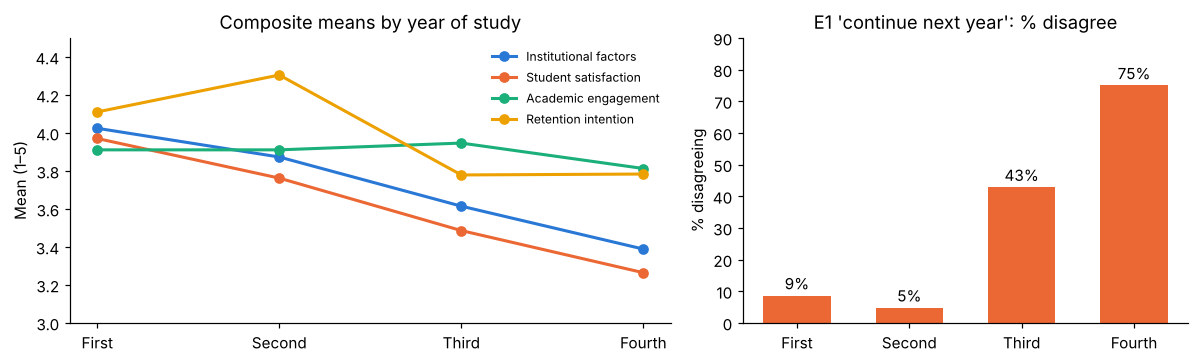

In [34]:
yb = df.groupby("year_c")[["IF", "SS", "AE", "RI"]].mean().reindex(yrs)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.35, 1]})
for k, c in [("IF", BLUE), ("SS", ORANGE), ("AE", AQUA), ("RI", YELLOW)]:
    axes[0].plot(yrs, yb[k], marker="o", color=c, lw=2, label=names[k])
axes[0].set(ylim=(3, 4.5), ylabel="Mean (1–5)", title="Composite means by year of study"); axes[0].legend(fontsize=8, frameon=False)
pct = [100 * (df.loc[df.year_c == g, "E1"] <= 2).mean() for g in yrs]
axes[1].bar(yrs, pct, color=ORANGE, width=.6)
for i, v in enumerate(pct): axes[1].text(i, v + 2, f"{v:.0f}%", ha="center")
axes[1].set(ylim=(0, 90), ylabel="% disagreeing", title="E1 'continue next year': % disagree")
plt.tight_layout(); plt.show()

## 16. Non-response bias check (Table 4.1)
Following Armstrong and Overton (1977), first-day respondents are compared with later respondents (a proxy for non-respondents).

In [35]:
df["wave"] = np.where(start.dt.date.astype(str).values == "2026-09-15", "Early", "Later")
display(pd.DataFrame({names[v]: two_group(v, "wave", "Early", "Later") for v in ["IF", "AE", "SS", "RI"]}).T)
ct = pd.crosstab(df.wave, df.year_c); chi = stats.chi2_contingency(ct)
print(f"Year-of-study composition by wave: χ²({chi[2]}) = {chi[0]:.2f}, p = {fmt_p(chi[1])}")
ct

,"Early: M (SD), n","other: M (SD), n",Welch t,Hedges' g [95% CI],Mann–Whitney p,Levene p,min. detectable d
Institutional factors,"3.87 (0.66), 75","3.79 (0.73), 43 [Later]","t(80.5) = 0.58, p = .560","0.11 [-0.26, 0.49]",.662,.549,0.54
Academic engagement,"3.89 (0.74), 76","3.94 (0.68), 43 [Later]","t(93.5) = -0.38, p = .703","-0.07 [-0.45, 0.30]",.894,.760,0.53
Student satisfaction,"3.74 (0.80), 76","3.77 (0.88), 43 [Later]","t(80.7) = -0.20, p = .843","-0.04 [-0.41, 0.34]",1.000,.299,0.53
Retention intention,"4.01 (0.81), 76","4.08 (0.65), 43 [Later]","t(103.9) = -0.52, p = .602","-0.09 [-0.47, 0.28]",.813,.078,0.53


Year-of-study composition by wave: χ²(3) = 9.08, p = .028


year_c,First,Fourth,Second,Third
wave,,,,
Early,34,5,13,24
Later,24,7,8,4


## 17. Exploratory item-level associations with retention intention (Table 4.14)
Spearman correlations of each predictor item with the retention-intention composite, with Bonferroni correction for 30 tests. Exploratory only — these show where further diagnostic work could focus, not causal drivers.

In [36]:
rows = {}
for c in B + C + D:
    x = df[[c, "RI"]].dropna(); r = stats.spearmanr(x[c], x["RI"])
    rows[c] = {"statement": item_text[c], "M": round(df[c].mean(), 2), "% agree": round(100 * (df[c].dropna() >= 4).mean(), 1),
               "ρ": round(r.statistic, 3), "p": fmt_p(r.pvalue), "Bonferroni p": fmt_p(min(1, r.pvalue * 30))}
items_ri = pd.DataFrame(rows).T.sort_values("ρ", ascending=False)
items_ri.head(10)

,statement,M,% agree,ρ,p,Bonferroni p
D5,I would recommend this institution to a friend or family member.,3.77,61.9,0.48,< .001,< .001
D1,"Overall, I am satisfied with my experience at this institution.",3.9,66.4,0.42,< .001,< .001
D10,"Overall, the quality of education at this institution is high.",4.03,71.4,0.397,< .001,< .001
C5,I feel motivated to succeed academically at this institution.,4.13,73.9,0.389,< .001,< .001
D9,The assessment methods used in my programme are fair and transparent.,3.89,70.6,0.353,< .001,.002
D2,My experience at this institution has met the expectations I had when I enrolled.,3.76,63.9,0.335,< .001,.006
D6,The support I have received has helped me manage the academic demands of my programme.,3.62,51.3,0.334,< .001,.006
D7,I feel that the institution treats students fairly and with respect.,3.86,69.5,0.333,< .001,.007
D8,The registration and student administration processes at this institution are efficient.,3.75,63.6,0.31,< .001,.019
B7,The institution communicates clearly and timeously about important academic matters.,3.94,68.6,0.304,< .001,.025


## 18. Summary of findings
* The three predictors jointly explain about **21.7%** of the variance in retention intention (Model 1).
* **Student satisfaction** is the only predictor with a significant unique association (β ≈ .51), robust to every alternative specification.
* Institutional factors and satisfaction correlate at **r ≈ .81** and load on the same factor, so their unique contributions cannot be cleanly separated.
* No significant differences in retention intention by employment, gender, funding, age or qualification; the apparent year-of-study difference is driven by item **E1**, which does not apply to final-year students.
* Satisfaction and institutional evaluations **decline across years of study**.
* The retention-intention scale has **low reliability (α ≈ .56)** — interpret all outcome-related estimates with caution.

In [37]:
# Optional: save the cleaned and scored data set for further work
df.to_csv("scored_data.csv", index=False)
print("Saved scored_data.csv with", df.shape[0], "rows and", df.shape[1], "columns")

Saved scored_data.csv with 119 rows and 65 columns
